In [9]:
from docx import Document

doc = Document("Timetable-REV5 Hypotheses re press coverage of Hepatitis C in UK.docx")
doc

In [10]:
def extract_only_bullets(docx_path):
    doc = Document(docx_path)
    bullet_points = []
    
    for paragraph in doc.paragraphs:
        pPr = paragraph._element.pPr
        
        if pPr is not None:
            numPr = pPr.find('.//{http://schemas.openxmlformats.org/wordprocessingml/2006/main}numPr')
            
            if numPr is not None:
                # Get the numId
                numId = numPr.find('.//{http://schemas.openxmlformats.org/wordprocessingml/2006/main}numId')
                
                if numId is not None:
                    num_id = numId.get('{http://schemas.openxmlformats.org/wordprocessingml/2006/main}val')
                    
                    # Check if it's a bullet (not numbered)
                    if is_bullet_list(doc, num_id):
                        bullet_points.append(paragraph.text)
    
    return bullet_points

def is_bullet_list(doc, num_id):
    """Check if a numbering ID corresponds to a bullet list"""
    try:
        numbering_part = doc.part.numbering_part
        numbering_xml = numbering_part.element
        
        # Find the num element with this numId
        num = numbering_xml.find(f'.//{{{numbering_xml.nsmap["w"]}}}num[@{{{numbering_xml.nsmap["w"]}}}numId="{num_id}"]')
        
        if num is not None:
            # Get the abstractNumId
            abstractNumId = num.find(f'.//{{{numbering_xml.nsmap["w"]}}}abstractNumId')
            abstract_num_id = abstractNumId.get(f'{{{numbering_xml.nsmap["w"]}}}val')
            
            # Find the abstractNum definition
            abstractNum = numbering_xml.find(f'.//{{{numbering_xml.nsmap["w"]}}}abstractNum[@{{{numbering_xml.nsmap["w"]}}}abstractNumId="{abstract_num_id}"]')
            
            if abstractNum is not None:
                # Check the first level's numFmt
                lvl = abstractNum.find(f'.//{{{numbering_xml.nsmap["w"]}}}lvl[@{{{numbering_xml.nsmap["w"]}}}ilvl="0"]')
                numFmt = lvl.find(f'.//{{{numbering_xml.nsmap["w"]}}}numFmt')
                
                # Bullet lists use 'bullet' format, numbered use 'decimal', 'lowerLetter', etc.
                fmt_val = numFmt.get(f'{{{numbering_xml.nsmap["w"]}}}val')
                return fmt_val == 'bullet'
    except:
        pass
    
    return False

In [11]:
bullets = extract_only_bullets("Timetable-REV5 Hypotheses re press coverage of Hepatitis C in UK.docx")
bullets

['1950: The Haemophilia Society (UK) was formed.',
 'Late 1980s: Early Treatments: Interferon was the first antiviral treatment for hepatitis C.  significant side effects and lower cure rates.',
 'Late 1980s: Victims and their families first started calling for compensation, often on the grounds of medical negligence, as more evidence is gathered about link between blood products and HIV/hepatitis infections',
 '1987. The Birchgrove Group (often referred to as the BirchGrove Society in contexts of support), which supports people with haemophilia, HIV, and Hepatitis C, established in Wales by a small group of patients at the University Hospital of Wales (UHW) in Cardiff.  Early 1990s expanded to a national level. ',
 'November 1987: announcement of £10 million payment for haemophiliacs infected with HIV',
 '7 March 1988: British Liver Trust incorporated and established.  (Founded by hepatologist Professor Dame Sheila Sherlock, leading charity for adults, focusing on raising awareness, p

In [12]:
import re

date_pattern = r'\b(?:' \
    r'\d{1,2}\s+(?:January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{4}|' \
    r'(?:Early|Mid|Late)\s+\d{4}s?|' \
    r'(?:January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{4}' \
    r')\b'

def extract_date(text):
    """Extract the date string from text"""
    match = re.search(date_pattern, text, re.IGNORECASE)
    if match:
        return match.group(0)
    return None

def remove_date(text, date_str):
    """Remove the date from the text and clean up extra whitespace"""
    cleaned = text.replace(date_str, '').strip()
    # Clean up any double spaces or extra punctuation left behind
    cleaned = re.sub(r'\s+', ' ', cleaned)
    cleaned = re.sub(r'^\s*[-:]\s*', '', cleaned)  # Remove leading dash or colon
    return cleaned

def group_bullets_by_date_dict(bullet_list):
    """Create dictionary with dates as keys and associated text as values"""
    date_dict = {}
    current_date = None
    
    for bullet in bullet_list:
        date_str = extract_date(bullet)
        
        if date_str:
            # This bullet has a date - start a new entry
            current_date = date_str
            # Remove date from text and make it the first element
            text_without_date = remove_date(bullet, date_str)
            date_dict[current_date] = [text_without_date]
        else:
            # This bullet doesn't have a date - add to current date's list
            if current_date:
                date_dict[current_date].append(bullet)
    
    return date_dict


In [13]:
grouped = group_bullets_by_date_dict(bullets)

In [14]:
grouped

{'Late 1980s': ['Victims and their families first started calling for compensation, often on the grounds of medical negligence, as more evidence is gathered about link between blood products and HIV/hepatitis infections'],
 'Early 1990s': ['1987. The Birchgrove Group (often referred to as the BirchGrove Society in contexts of support), which supports people with haemophilia, HIV, and Hepatitis C, established in Wales by a small group of patients at the University Hospital of Wales (UHW) in Cardiff. expanded to a national level.'],
 'November 1987': ['announcement of £10 million payment for haemophiliacs infected with HIV'],
 '7 March 1988': ['British Liver Trust incorporated and established. (Founded by hepatologist Professor Dame Sheila Sherlock, leading charity for adults, focusing on raising awareness, providing support, and campaigning for improved early detection and treatment of liver disease)'],
 '10 March 1988': ['Macfarlane Trust established',
  'April 21, 1989: ‘Discovery’/id

In [15]:
import pandas as pd

df = pd.read_csv("./chunked_press_review.csv")
df['Date'] = pd.to_datetime(df['Date'].apply(lambda x: x.replace(" 00:00:00", "")))
articles = df.groupby(["Title", "Date", "Author", "Newspaper", "Source", "newspaper_type"])['chunks'].apply(lambda x: " ".join(x).replace("  ", " ")).reset_index()
articles = articles.sort_values(["Date"])
articles

,Title,Date,Author,Newspaper,Source,newspaper_type,chunks
5130,International Companies: Technology - Pounds 2...,1983-02-11,DAVID FISHLOCK,Financial Times,Factiva - HepC,broadsheet,BRITAIN'S biotechnologists are to have a new P...
8257,Study confirms fears on spread of Aids,1984-08-31,ANDREW VEITCH,The Guardian,Lexis-Nexis - Times,broadsheet,Fears that the Aids virus is widespread among ...
5894,Maternity unit where waste parades the corrido...,1984-10-20,No author in byline,The Guardian,Lexis-Nexis - Times,broadsheet,Dawn in the Rosie maternity unit at the 900-be...
7433,Prisons inspector condemns sanitary conditions...,1984-10-24,AILEEN BALLANTYNE,The Guardian,Lexis-Nexis - Times,broadsheet,Gaol conditions fall short of the standard exp...
3509,Financial Times Survey: China - Business - Gro...,1984-10-29,No author in byline,Financial Times,Factiva - HepC,broadsheet,CLIMATENorth China (including Beijing) - Winte...
...,...,...,...,...,...,...,...
3750,Gangsters muscle in on Scotland’s beauty industry,2024-07-14,David Leask,thetimes.co.uk,Factiva - HepC,broadsheet,The lack of regulation surrounding cosmetic in...
5108,Inside the Filipino jails struggling to contai...,2024-07-15,Sarah Newey,Telegraph Online,Factiva - HepC,broadsheet,"As Covid showed, prisons can act as incubators..."
6765,No title found,2024-08-17,No author found,Daily Worker / Morning Star,UKPressOnline,other,Confusion over infected blood payouts as victi...
6766,No title found,2024-09-13,No author found,Daily Star,UKPressOnline,tabloid,Hope for a chronic virus cure. BOFFINS are clo...


In [39]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("/Users/pnadel01/fp_models/google_embeddinggemma-300m", device="cpu")

In [40]:
# test key: '29 August 2003'

sent_sim_template = "task: sentence similarity | query: {content}"

associated_text = grouped['29 August 2003']
query_embedding = model.encode(sent_sim_template.format(content=associated_text))
query_embedding.shape

(768,)

In [41]:
associated_text

['Health Secretary pledges payments to people infected with HCV: PWHCV acute stage got nothing; £20,000 to PW chronic (stage 1) HCV; further £25,000 to PW (stage 2) HCV']

In [42]:
times = articles[articles.Newspaper == "The Times"]
times

,Title,Date,Author,Newspaper,Source,newspaper_type,chunks
9040,Travel: How to stay healthy on your summer bre...,1985-07-06,ISABEL WALKER,The Times,Factiva - HepC,broadsheet,Holidays are one of the 30 most stressful even...
3436,Family Money: Taking the sting from jabs / Ino...,1985-08-03,VIVIEN GOLDSMITH,The Times,Factiva - HepC,broadsheet,The series of jabs you will need if you are of...
994,A BREAKDOWN OF THE BREAKDOWNS (732),1985-08-14,JOHN GOODBODY,The Times,Factiva - HepC,broadsheet,Steve Cram1981Has a winter of injuries.August:...
8974,Times Diary: Les-majeste (105),1985-08-30,PHS,The Times,Factiva - HepC,broadsheet,After years of pretending to find Barry Humphr...
1800,Blood tests could fail to identify Aids virus ...,1985-09-30,No author in byline,The Times,Factiva - HepC,broadsheet,Aids-infected blood could fail to be detected ...
...,...,...,...,...,...,...,...
7310,Pillars of the state let down patients for hal...,2024-05-21,Kaya Burgess,The Times,Factiva - HepC,broadsheet,"Doctors, health officials, the NHS, civil serv..."
8912,They came with dignity and seeking vindication,2024-05-21,Tom Peck,The Times,Factiva - HepC,broadsheet,"T hey looked, at first, like a Cup Final crowd..."
5039,Infected blood victims came with dignity and s...,2024-05-21,Tom Peck,The Times,Semi automated,broadsheet,"There was joy, but just below the surface ther..."
1109,"A standing ovation, a mea culpa — but now more...",2024-05-21,Tom Peck,The Times,Semi automated,broadsheet,"Infected blood victims, their families and cam..."


In [43]:
key_dt = pd.to_datetime('29 August 2003')
buffer = pd.DateOffset(years=1)

In [44]:
zone_of_interest = times[(times.Date >= key_dt) & (times.Date <= key_dt + buffer)]
zone_of_interest 

,Title,Date,Author,Newspaper,Source,newspaper_type,chunks
7378,Pounds 100m deal for blood victims,2003-08-30,Oliver Wright Health Correspondent,The Times,Factiva - HepC,broadsheet,THE Government is to pay Pounds 100 million in...
2239,Cash hopes for hepatitis victims,2003-08-30,No author in byline,The Times,Factiva - HepC,broadsheet,THE campaign to win compensation payments for ...
8865,The top stories,2003-09-02,No author in byline,The Times,Factiva - HepC,broadsheet,1 The number of people applying for asylum in ...
9986,tuberculosis;New medical research,2003-09-09,No author in byline,The Times,Factiva - HepC,broadsheet,People who adopt children internationally run ...
8529,Tattoo warning;In brief,2003-09-18,No author in byline,The Times,Factiva - HepC,broadsheet,Machinery used to etch semi-permanent tattoos ...
7237,Permanent Tattoos;Lunchtime Fix;Shopping,2003-09-27,Curly Moore,The Times,Factiva - HepC,broadsheet,They are so popular that you can even have one...
2136,Calls for hepatitis C inquiry,2003-09-30,No author in byline,The Times,Factiva - HepC,broadsheet,MINISTERS are facing fresh demands for a publi...
3004,Down in the mouth;NB;Health,2003-10-01,No author in byline,The Times,Factiva - HepC,broadsheet,Hepatitis C can be passed on by sharing toothb...
8259,Stung into action;Science,2003-10-02,Anjana Ahuja,The Times,Factiva - HepC,broadsheet,AS MICROSOFT CHIEF BILL GATES DONATES Pounds 1...
6361,Need to know;Global business briefing,2003-10-14,Edited by Neelam Verjee,The Times,Factiva - HepC,broadsheet,Economics * The rise of the FTSE 100 index to...


In [45]:
doc_texts = [t.Title + "\n" + t.chunks for t in zone_of_interest.itertuples()]
doc_embeddings = model.encode([sent_sim_template.format(content=text) for text in doc_texts])
doc_embeddings.shape

(54, 768)

In [46]:
sim_scores = doc_embeddings @ query_embedding.T
rel_ids_and_scores =[(i, sim_scores[i]) for i in (sim_scores).argsort()[::-1]]
rel_ids_and_scores

[(np.int64(23), np.float32(0.71727693)),
 (np.int64(1), np.float32(0.69857454)),
 (np.int64(14), np.float32(0.6736256)),
 (np.int64(24), np.float32(0.67345923)),
 (np.int64(6), np.float32(0.6596087)),
 (np.int64(35), np.float32(0.6530088)),
 (np.int64(0), np.float32(0.6408417)),
 (np.int64(7), np.float32(0.61350024)),
 (np.int64(31), np.float32(0.5980351)),
 (np.int64(42), np.float32(0.59765714)),
 (np.int64(18), np.float32(0.59198344)),
 (np.int64(27), np.float32(0.5902797)),
 (np.int64(21), np.float32(0.5696466)),
 (np.int64(26), np.float32(0.56456965)),
 (np.int64(46), np.float32(0.55722904)),
 (np.int64(19), np.float32(0.5558704)),
 (np.int64(3), np.float32(0.54863423)),
 (np.int64(4), np.float32(0.5449147)),
 (np.int64(41), np.float32(0.5332698)),
 (np.int64(34), np.float32(0.5245775)),
 (np.int64(20), np.float32(0.50968814)),
 (np.int64(10), np.float32(0.5030689)),
 (np.int64(17), np.float32(0.5004462)),
 (np.int64(8), np.float32(0.4988917)),
 (np.int64(2), np.float32(0.4950566))

In [ ]:
from pprint import pprint

i = rel_ids_and_scores[0][0]

print(i)
print(zone_of_interest.iloc[i].Title)
print(zone_of_interest.iloc[i].Date) # 24 January 2004
pprint(zone_of_interest.iloc[i].chunks)
pprint(associated_text) # 29 August 2003

23
NHS hepatitis victims to get up to Pounds 45,000   
2004-01-24 00:00:00
('PATIENTS infected with hepatitis C after being given blood by the NHS will '
 'receive payments of up to Pounds 45,000 each, the Government said yesterday. '
 'The scheme, outlined by John Reid, the Health Secretary, will also include '
 'patients cleared of the virus through treatment and others who caught the '
 'virus from someone infected by NHS blood or blood products. But the '
 'Department of Health, which plans to start the scheme in April, was accused '
 'last night of a gross oversight for excluding widows of haemophiliacs who '
 'had died from the disease as a result. Lord Morris of Manchester, the Labour '
 'peer and president of the Haemophilia Society, said that the omission was '
 'symptomatic of a scheme that fell far short of the benefits offered by other '
 'governments around the world. Dr Reid announced his intention to award '
 'ex-gratia payments to British hepatitis C victims last August

In [48]:
import numpy as np

def scale_score(sim_scores, item_dates, target_date, scaler_func, date_weight):
    sim_scores = np.array(sim_scores)
    days_diffs = np.abs(np.array([(target_date - d).days for d in item_dates]))
    date_scores = np.array([scaler_func(d) for d in days_diffs])
    composite = (1 - date_weight) * sim_scores + date_weight * date_scores
    return composite, date_scores

def inverse_square(days_diff, max_days=365):
    normalized_diff = days_diff / max_days
    return 1 / (1 + normalized_diff ** 2)

In [49]:
rel_ids_and_scores

[(np.int64(23), np.float32(0.71727693)),
 (np.int64(1), np.float32(0.69857454)),
 (np.int64(14), np.float32(0.6736256)),
 (np.int64(24), np.float32(0.67345923)),
 (np.int64(6), np.float32(0.6596087)),
 (np.int64(35), np.float32(0.6530088)),
 (np.int64(0), np.float32(0.6408417)),
 (np.int64(7), np.float32(0.61350024)),
 (np.int64(31), np.float32(0.5980351)),
 (np.int64(42), np.float32(0.59765714)),
 (np.int64(18), np.float32(0.59198344)),
 (np.int64(27), np.float32(0.5902797)),
 (np.int64(21), np.float32(0.5696466)),
 (np.int64(26), np.float32(0.56456965)),
 (np.int64(46), np.float32(0.55722904)),
 (np.int64(19), np.float32(0.5558704)),
 (np.int64(3), np.float32(0.54863423)),
 (np.int64(4), np.float32(0.5449147)),
 (np.int64(41), np.float32(0.5332698)),
 (np.int64(34), np.float32(0.5245775)),
 (np.int64(20), np.float32(0.50968814)),
 (np.int64(10), np.float32(0.5030689)),
 (np.int64(17), np.float32(0.5004462)),
 (np.int64(8), np.float32(0.4988917)),
 (np.int64(2), np.float32(0.4950566))

In [50]:
composite, date_scores = scale_score(sim_scores, zone_of_interest.Date, key_dt, inverse_square, 0.5)
composite, date_scores 

(array([0.82041711, 0.84928352, 0.74746826, 0.77386341, 0.77096064,
        0.70719796, 0.82599055, 0.80269619, 0.74514465, 0.68436014,
        0.74232466, 0.69369088, 0.63252859, 0.71161998, 0.82234788,
        0.69583449, 0.67714774, 0.73248554, 0.77676095, 0.74237331,
        0.71662916, 0.73383377, 0.59779043, 0.78803916, 0.76283418,
        0.64661083, 0.69573431, 0.70255326, 0.56553862, 0.64158968,
        0.62422691, 0.68356077, 0.55125053, 0.52576011, 0.60961055,
        0.66510472, 0.47932077, 0.54591573, 0.47916991, 0.47112415,
        0.50938174, 0.56184943, 0.59245551, 0.46079239, 0.47561465,
        0.47815719, 0.55523417, 0.4537707 , 0.47786551, 0.45978221,
        0.46542568, 0.48707763, 0.44014273, 0.46624659]),
 array([0.99999249, 0.99999249, 0.99987992, 0.99909259, 0.99700655,
        0.99372697, 0.99237238, 0.99189213, 0.99139759, 0.98436542,
        0.9815804 , 0.97935075, 0.97935075, 0.97619327, 0.97107016,
        0.97017208, 0.96645605, 0.96452489, 0.96153846, 0.

In [51]:
i = composite.argsort()[::-1][0]

print(i)
print(zone_of_interest.iloc[i].Title)
print(zone_of_interest.iloc[i].Date)
pprint(zone_of_interest.iloc[i].chunks)

pprint(associated_text)

1
Cash hopes for hepatitis victims
2003-08-30 00:00:00
('THE campaign to win compensation payments for Scots infected with hepatitis '
 'C from infected NHS blood products took an important step forward yesterday '
 'as the Scottish Executive announced that the UK Government had agreed that '
 'such payments could be made by the devolved body.Malcolm Chisholm, '
 "Scotland's Health Minister, said that a similar scheme was being established "
 'in England by the Department of Health.A stumbling block to implementing any '
 'such scheme remains, however, because the Department of Work and Pensions in '
 'Whitehall has given no guarantee that it will not claw back social security '
 'payments from hepatitis victims given compensation.Under the proposed scheme '
 'in Scotland, ex gratia payments of Pounds 20,000 would be made to all those '
 'who have the hepatitis C virus as a result of infected NHS blood products. A '
 'further Pounds 25,000 would go to to those in an advanced stage of '

In [52]:
# next steps: all times with specific dates, refine thresholds, scale sim score by date

In [66]:
articles.Newspaper.unique()

array(['Financial Times', 'The Guardian', 'The Times', 'The Sunday Times',
       'The Evening Standard', 'The Daily Telegraph', 'The Independent',
       'The Daily Mail', 'The Daily Mirror', 'The Daily Express',
       'The Observer', 'The Sunday Telegraph', 'Independent On Sunday',
       'The Sunday Mirror', 'The Mail on Sunday', 'The Sun', 'People',
       'Daily Worker / Morning Star', 'Daily Star',
       'The Express on Sunday', 'Financial Times (FT.Com)',
       'Daily Star Sunday', 'Metro', 'thetimes.co.uk', 'Telegraph Online',
       'thesun.co.uk', 'Mail Online', 'dailystar.co.uk',
       'The Sunday Express', 'Mirror.co.uk', 'The US Sun',
       'The Standard Online', 'express.co.uk', 'The Telegraph',
       'The Mirror', 'iNews', 'sundaytimes.co.uk', 'Evening Standard',
       'Sunday People'], dtype=object)

In [162]:
def get_article_from_chron_item(chron_key, newspaper="Financial Times", include_score=.7, week_offset=52):
    associated_text = grouped[chron_key]
    query_embedding = model.encode(sent_sim_template.format(content=associated_text))
    newspaper_articles = articles[articles.Newspaper == newspaper]
    
    key_dt = pd.to_datetime(chron_key)
    buffer = pd.DateOffset(weeks=week_offset)
    zone_of_interest = newspaper_articles[(newspaper_articles.Date >= key_dt) & (newspaper_articles.Date <= key_dt + buffer)]
    doc_texts = [t.Title + "\n" + t.chunks for t in zone_of_interest.itertuples()]
    doc_embeddings = model.encode([sent_sim_template.format(content=text) for text in doc_texts])
    sim_scores = doc_embeddings @ query_embedding.T

    composite, _ = scale_score(sim_scores, zone_of_interest.Date, key_dt, inverse_square, 0.5)
    rel_ids_and_scores = [(i, composite[i]) for i in (composite).argsort()[::-1]]
    i = composite.argsort()[::-1][0]
    rel_score = rel_ids_and_scores[i][1]

    # print(i)
    # print(zone_of_interest.iloc[i].Title)
    # print(rel_score)
    if rel_score > include_score:
        # print(zone_of_interest.iloc[i].Date)
        # pprint(zone_of_interest.iloc[i].chunks)
        # pprint(associated_text)
        return 1
    else:
        # print("Article not relevant enough.")
        # pprint(associated_text)
        return 0


In [163]:
grouped.keys()

dict_keys(['Late 1980s', 'Early 1990s', 'November 1987', '7 March 1988', '10 March 1988', 'July 1988', 'June 1989', '29 January 1990', 'April 1991', '3 May 1991', 'Sept 1991', '17 February 1992', '27 April 1992', '29 March 1993', 'May 1993', '11 July 1995', '26 March 2001', 'August 2001', 'June 2002', '20 January 2003', '29 August 2003', 'January 2004', '25 March 2004', 'January 2006', 'July 2006', '19 February 2007', 'March 2007', '23 April 2008', 'February 2009', 'March 2009', '20 May 2009', 'April 2010', '14 October 2010', 'January 2011', '8 March 2011', '22 June 2011', 'May 2011', 'October 2011', 'November 2013', 'December 2013', 'April 2014', 'August 2014', 'October 2014', 'March 2015', '25 March 2015', 'October 2015', 'November 2015', 'June 2016', 'January 2017', '11 July 2017', 'August 2017', 'May 2018', '2 July 2018', '5 October 2020', '10 December 2020', '20 May 2024', '31 March 2025', '9 July 2025', '21 July 2025', '30 October 2025', 'November 2025', '31 December 2025', '22 J

In [164]:
from tqdm import tqdm

event_counts = []

for newspaper in tqdm(articles.Newspaper.unique()):
    for date in grouped: 
        full_date_format_check = re.search(r"\d{2}\s[A-z]+\s\d{4}",date)
        general_date_format_check = re.search(r"[A-z]+\s\d{4}",date)
        if full_date_format_check:
            offset = 52
        elif general_date_format_check and ("Early" not in date or "Late" not in date):
            offset = 114
        else:
            offset = 228
        try:
            score = get_article_from_chron_item(date, newspaper=newspaper, include_score=.73, week_offset=offset)
            event_counts.append((newspaper, date, score))
        except Exception as e:
            pass

100%|██████████| 39/39 [2:16:47<00:00, 210.44s/it]  


In [165]:
present_articles = pd.DataFrame(event_counts, columns=["newspaper", "date", "article_there"])
present_articles

,newspaper,date,article_there
0,Financial Times,November 1987,0
1,Financial Times,7 March 1988,1
2,Financial Times,10 March 1988,1
3,Financial Times,July 1988,0
4,Financial Times,June 1989,0
...,...,...,...
1073,Evening Standard,2 July 2018,0
1074,Sunday People,January 2017,0
1075,Sunday People,August 2017,0
1076,Sunday People,May 2018,0


In [1]:
import pandas as pd 
present_articles = pd.read_csv("present_articles225.csv")

In [2]:
present_articles[present_articles.newspaper == "The Evening Standard"]

,Unnamed: 0,newspaper,date,article_there,date_as_dt,Newspaper,newspaper_type,newspaper_size
210,192440,The Evening Standard,November 1987,0,1987-11-01,The Evening Standard,tabloid,227
211,192667,The Evening Standard,7 March 1988,1,1988-03-07,The Evening Standard,tabloid,227
212,192894,The Evening Standard,10 March 1988,0,1988-03-10,The Evening Standard,tabloid,227
213,193121,The Evening Standard,July 1988,0,1988-07-01,The Evening Standard,tabloid,227
214,193348,The Evening Standard,June 1989,1,1989-06-01,The Evening Standard,tabloid,227
215,193575,The Evening Standard,April 1991,1,1991-04-01,The Evening Standard,tabloid,227
216,193802,The Evening Standard,3 May 1991,1,1991-05-03,The Evening Standard,tabloid,227
217,194029,The Evening Standard,11 July 1995,0,1995-07-11,The Evening Standard,tabloid,227
218,194256,The Evening Standard,26 March 2001,1,2001-03-26,The Evening Standard,tabloid,227
219,194483,The Evening Standard,August 2001,0,2001-08-01,The Evening Standard,tabloid,227


In [3]:
date_relevance = present_articles[present_articles.article_there > 0].groupby('date').size()

In [16]:
list(articles.Newspaper.unique()[:5])

['Financial Times',
 'The Guardian',
 'The Times',
 'The Sunday Times',
 'The Evening Standard']

In [17]:
grouped['11 July 2017'][0]

'Theresa May ordered a new inquiry into how more than 2,400 people died in Britain from hepatitis C and HIV/AIDS after receiving transfusions of government-supplied tainted blood products in the 1970s and 1980s.'

In [18]:
july_11 = articles[articles.Date == pd.to_datetime("11 July 2017")]
july_11[july_11.newspaper_type == 'tabloid']

,Title,Date,Author,Newspaper,Source,newspaper_type,chunks
5904,May announces inquiry into contaminated blood ...,2017-07-11,No author in byline,Mail Online,Factiva - HepC,tabloid,"* Estimated 2,400 people died after they recei..."
5903,May announces inquiry into contaminated blood ...,2017-07-11,"JAMES TAPSFIELD, POLITICAL EDITOR FOR MAILONLINE",The Daily Mail,Semi automated,tabloid,"* Estimated 2,400 people died after they recei..."
709,"'I'm over the moon': Mother of boy, seven, who...",2017-07-11,"BEN SPENCER, MEDICAL CORRESPONDENT FOR THE DAI...",The Daily Mail,Semi automated,tabloid,* Colin Smith died of Aids at age of seven aft...
710,"'I'm over the moon': Mother of boy, seven, who...",2017-07-11,No author in byline,Mail Online,Factiva - NANBH,tabloid,* Colin Smith died of Aids at age of seven aft...
5765,MPS TO DEBATE 'CRIMINAL COVER-UP' IN CONTAMINA...,2017-07-11,BEN SPENCER,The Daily Mail,Factiva - HepC,tabloid,PARLIAMENT is to hold an emergency debate on t...
632,'Finally we have the chance for justice': Fami...,2017-07-11,Ben Glaze,Mirror.co.uk,Factiva - HepC,tabloid,The Prime Minister finally agreed to demands f...
633,'Finally we have the chance for justice': Fami...,2017-07-11,By Ben Glaze,The Mirror,Semi automated,tabloid,The Prime Minister finally agreed to demands f...
4799,I'VE LOST EVERY HAIR ON MY HEAD AND BODY,2017-07-11,BY DR MARTIN SCURR,The Daily Mail,Semi automated,tabloid,I have gradually lost all the hair on my head ...
2444,Contaminated blood scandal: Theresa May announ...,2017-07-11,Francesca Gillett,The Evening Standard,Factiva - HepC,tabloid,An inquiry is to be launched into the contamin...


In [19]:
july_11[july_11.newspaper_type == 'broadsheet']

,Title,Date,Author,Newspaper,Source,newspaper_type,chunks
8910,Theresa May orders contaminated blood scandal ...,2017-07-11,Peter Walker and Alexandra Topping,The Guardian,Factiva - HepC,broadsheet,"Inquiry to look into deaths of 2,400 people af..."
7410,Prime Minister announces inquiry into contamin...,2017-07-11,Kate McCann,Telegraph Online,Factiva - HepC,broadsheet,Theresa May has ordered an inquiry into the co...
7409,Prime Minister announces inquiry into contamin...,2017-07-11,"By Kate McCann, Senior Political Correspondent",The Telegraph,Semi automated,broadsheet,Theresa May has ordered an inquiry into the co...
2758,David Davis rejects claims government has soft...,2017-07-11,Andrew Sparrow,The Guardian,Factiva - HepC,broadsheet,Rolling coverage of the days political develop...
5099,Inquiry ordered into contaminated blood scandal,2017-07-11,No author in byline,thetimes.co.uk,Factiva - HepC,broadsheet,Theresa May has ordered an inquiry into how th...
3040,Drug companies challenge NHS rationing plan in...,2017-07-11,Chris Smyth,The Times,Semi automated,broadsheet,The pharmaceutical industry is taking the NHS ...
5098,Inquiry ordered into contaminated blood scandal,2017-07-11,"Henry Zeffman, Political Reporter",The Times,Semi automated,broadsheet,Theresa May has ordered an inquiry into how th...
8495,Tainted blood scandal inquiry ordered by May,2017-07-11,"Henry Zeffman, Political Reporter",The Times,Semi automated,broadsheet,Theresa May has ordered an inquiry into how th...
1332,An arbitrary benchmark for access to new drugs...,2017-07-11,No author in byline,Financial Times,Semi automated,broadsheet,There has been no lack of agonising over the f...
7323,"Plasma donors were prisoners, addicts and pros...",2017-07-11,No author in byline,thetimes.co.uk,Factiva - HepC,broadsheet,At the centre of the tainted blood scandal was...


In [20]:
import pprint
print(july_11[july_11.newspaper_type == 'broadsheet'].iloc[8].Title)
pprint.pprint(july_11[july_11.newspaper_type == 'broadsheet'].iloc[8].chunks)

An arbitrary benchmark for access to new drugs; Policy is an admission the UK cannot afford to be at the cutting edge
("There has been no lack of agonising over the financial strains on England's "
 'National Health Service , whether the results are seen in chronic bed '
 'shortages, longer waiting times, or decisions to deny surgery to smokers. '
 'Yet a policy change that would allow NHS managers to ration access to '
 'expensive new treatments, even when they have been judged cost-effective, '
 'has largely escaped attention. Now, the drugs industry is resorting to legal '
 'action to try to overturn the policy. At issue is the introduction of a '
 '"budget impact test" in the process for evaluating new drugs. Until now, the '
 'National Institute for Health and Care Excellence (Nice) has tended to '
 'recommend adoption of all new drugs it deems to be cost effective, measured '
 'as cost per additional year of quality-adjusted life (Qaly). It uses a '
 'threshold of about 20,000 to

In [21]:
present_articles['date_as_dt'] = pd.to_datetime(present_articles['date'])

/var/folders/ym/47gs2t6156v0mmn_wczlfpp00000gs/T/ipykernel_19550/3021902463.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  present_articles['date_as_dt'] = pd.to_datetime(present_articles['date'])


In [22]:
present_articles['newspaper_size'] = present_articles.apply(lambda x: len(articles[articles['Newspaper'] == x['newspaper']]), axis=1)

In [23]:
present_articles

,Unnamed: 0,newspaper,date,article_there,date_as_dt,Newspaper,newspaper_type,newspaper_size
0,0,Financial Times,November 1987,0,1987-11-01,Financial Times,broadsheet,811
1,811,Financial Times,7 March 1988,1,1988-03-07,Financial Times,broadsheet,811
2,1622,Financial Times,10 March 1988,1,1988-03-10,Financial Times,broadsheet,811
3,2433,Financial Times,July 1988,0,1988-07-01,Financial Times,broadsheet,811
4,3244,Financial Times,June 1989,0,1989-06-01,Financial Times,broadsheet,811
...,...,...,...,...,...,...,...,...
1192,426681,Evening Standard,2 July 2018,0,2018-07-02,Evening Standard,tabloid,2
1193,426683,Sunday People,January 2017,0,2017-01-01,Sunday People,tabloid,11
1194,426694,Sunday People,August 2017,0,2017-08-01,Sunday People,tabloid,11
1195,426705,Sunday People,May 2018,0,2018-05-01,Sunday People,tabloid,11


<Axes: ylabel='date_as_dt'>

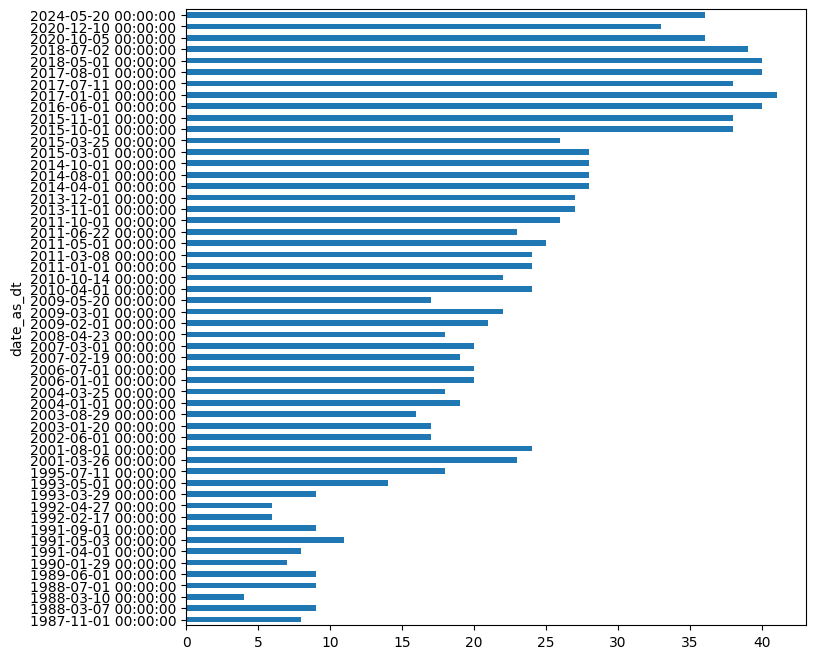

In [24]:
present_articles.sort_values('date_as_dt').groupby('date_as_dt').count().newspaper.plot(kind="barh", figsize=(8,8))

<Axes: ylabel='newspaper'>

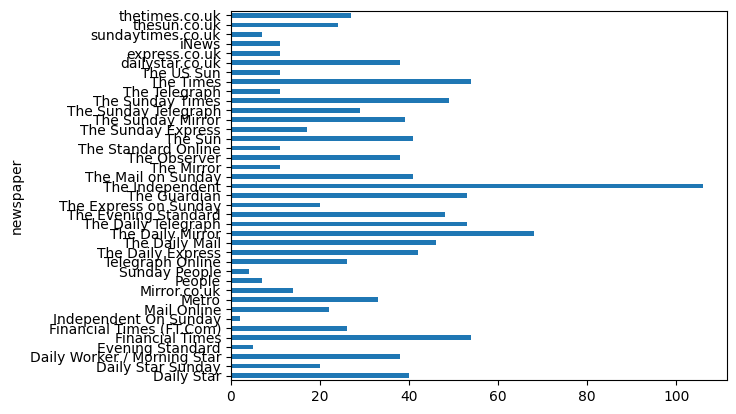

In [25]:
present_articles.groupby('newspaper').count().date.plot(kind="barh")

In [26]:
present_articles = present_articles.merge(articles[["Newspaper", "newspaper_type"]], left_on="newspaper", right_on="Newspaper").drop_duplicates() 

In [27]:
present_articles = present_articles.rename(columns={"Newspaper_x":"Newspaper", "newspaper_type_x":"newspaper_type"})

<Axes: ylabel='newspaper'>

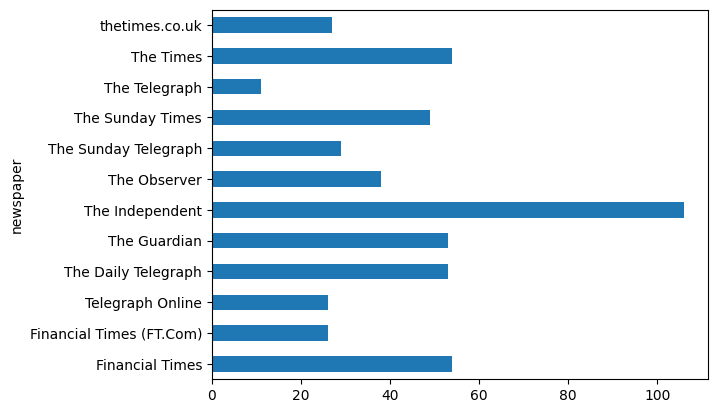

In [28]:
present_articles[present_articles.newspaper_type == "broadsheet"].groupby('newspaper').count().date.plot(kind="barh")

<Axes: ylabel='newspaper'>

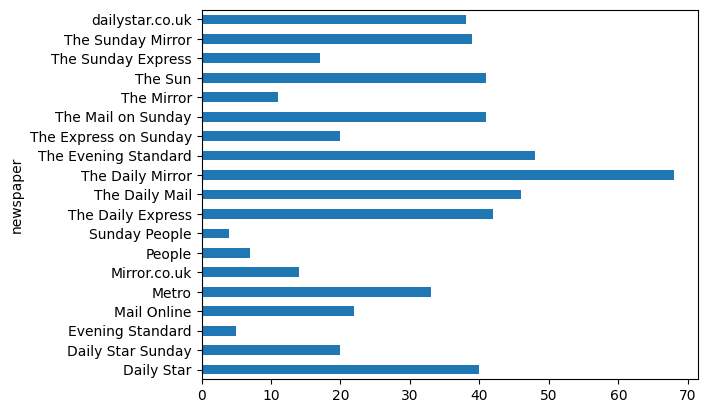

In [29]:
present_articles[present_articles.newspaper_type == "tabloid"].groupby('newspaper').count().date.plot(kind="barh")

In [30]:
present_articles

,Unnamed: 0,newspaper,date,article_there,date_as_dt,Newspaper,newspaper_type,newspaper_size,Newspaper_y,newspaper_type_y
0,0,Financial Times,November 1987,0,1987-11-01,Financial Times,broadsheet,811,Financial Times,broadsheet
811,811,Financial Times,7 March 1988,1,1988-03-07,Financial Times,broadsheet,811,Financial Times,broadsheet
1622,1622,Financial Times,10 March 1988,1,1988-03-10,Financial Times,broadsheet,811,Financial Times,broadsheet
2433,2433,Financial Times,July 1988,0,1988-07-01,Financial Times,broadsheet,811,Financial Times,broadsheet
3244,3244,Financial Times,June 1989,0,1989-06-01,Financial Times,broadsheet,811,Financial Times,broadsheet
...,...,...,...,...,...,...,...,...,...,...
484761,426681,Evening Standard,2 July 2018,0,2018-07-02,Evening Standard,tabloid,2,Evening Standard,tabloid
484763,426683,Sunday People,January 2017,0,2017-01-01,Sunday People,tabloid,11,Sunday People,tabloid
484774,426694,Sunday People,August 2017,0,2017-08-01,Sunday People,tabloid,11,Sunday People,tabloid
484785,426705,Sunday People,May 2018,0,2018-05-01,Sunday People,tabloid,11,Sunday People,tabloid


In [31]:
present_articles.to_csv("present_articles225.csv")

In [32]:
import json

with open("grouped.json", "w") as f:
    json.dump(grouped, f)